# Quem está falando? MFCC × YAMNet sob reverberação

**IA940/EG940 · Análise e Síntese de Sinais Musicais · UNICAMP · 2s2026 · Prof. Bruno Masiero**
Grupo: Kevin Inofuente Colque, Luiza Viana Souza, Guilherme Maia Masetto · **Trilha Voz**

**Pergunta.** Na identificação de locutor com kNN, como cai a acurácia de uma representação clássica (**vetor de MFCC médios**, 20-d) e de uma representação aprendida (**embedding do YAMNet**, 1024-d) quando a voz é reverberada de forma controlada (RT60 de 0 a 2 s)?

**Roteiro do notebook**
1. Previsão registrada (23/10)
2. Banco de dados e cuidado contra vazamento
3. Representações e classificação sem degradação
4. Degradação: reverberação por convolução com RI sintética (equações, verificação e áudios)
5. Resultado central: acurácia × RT60, com variabilidade
6. Por que as curvas fazem o que fazem (diagnósticos)
7. Análise de falhas com exemplos audíveis
8. Previsto × observado e conclusões

Todo o código está em `src/` e é importado aqui; as features já extraídas ficam em `data/` (a extração completa leva ≈ 4 min por nível de RT60 num MacBook M3 Pro). Para regerar tudo do zero:
```bash
python -m src.extract --esd ~/Datasets/ESD/"Emotion Speech Dataset" --saida data/features
python -m src.extract_reverb                       # 8 níveis de RT60
python -m src.extract_reverb --cortar-cauda --saida data/features_reverb_semcauda --niveis 0.2 0.5 1.0 2.0
```

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa, librosa.display
from IPython.display import Audio, display, Markdown

from src.degradation import (NIVEIS_RT60, resposta_impulso, rt60_medido, drr_db,
                             reverberar, semente_arquivo, ganho_cauda)
from src.features import carregar_audio, SR
from src.classify import gerar_divisoes
from src.curves import carregar, avaliar_curvas, resumo_pareado
from src.failures import (geometria, scores_yamnet, f0_mediana_por_locutor,
                          categorias_acerto, exportar_exemplos, deslocamento_mfcc)

K, N_DIVISOES = 5, 5
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
COR = {"MFCC": "#1f77b4", "YAMNet": "#d62728"}

## 1. Previsão registrada (23/10, antes de rodar qualquer degradação)

Texto do slide 6 da apresentação de 23/10 ([esd-proyecto.vercel.app](https://esd-proyecto.vercel.app)), transcrito sem alterações:

> **Hipótese.** A acurácia cai com a reverberação nos dois casos, mas o **YAMNet cai mais devagar que o MFCC**.
>
> **Justificativa.**
> • MFCC usa janelas de ≈ 25 ms; a cauda da reverberação dura centenas de ms, mistura quadros vizinhos e borra a prosódia (energia, pausas, ritmo).
> • YAMNet foi pré-treinado no AudioSet (≈ 2 milhões de clipes do YouTube, gravados em ambientes muito variados) e recebe áudio a 16 kHz, como o ESD.

O esboço tinha duas curvas logísticas (escolhidas à mão): as duas partindo de valores altos, o MFCC caindo a partir de RT60 ≈ 0,3–0,5 s e o YAMNet caindo mais tarde e mais devagar.

**Atualização de 06/11 (já com a classificação sem degradação, ainda sem reverberação).** O YAMNet partiu de 55 % e não de um valor alto, e o MFCC de 98 %. A previsão sobre a **inclinação** foi mantida (o YAMNet cairia mais devagar); a pergunta passou a ser se a curva do MFCC cairia até cruzar a do YAMNet. A discussão do que divergiu está na seção 8.

## 2. Banco de dados

**ESD — Emotional Speech Dataset** (Zhou et al., *Speech Communication* 137, 2022). Usamos os **10 locutores de inglês (0011–0020)**: cada um lê as **mesmas 350 frases** em 5 emoções (Neutral, Angry, Happy, Sad, Surprise) → 1 750 áudios por locutor, **17 500 no total**, 16 kHz mono, gravados em estúdio (SNR > 20 dB). O rótulo é o **locutor**, tirado do nome do arquivo (a pasta é a emoção). Acaso = 10 %.

In [2]:
meta, y, X = carregar()                      # X[(representação, RT60)] -> matriz (17500, d)
display(pd.crosstab(meta.locutor, meta.emocao, margins=True, margins_name="total"))
dur = np.array([librosa.get_duration(path=c) for c in meta.caminho[::25]])
print(f"duração (amostra de {len(dur)} arquivos): média {dur.mean():.2f} s, "
      f"mín {dur.min():.2f} s, máx {dur.max():.2f} s")

emocao,Angry,Happy,Neutral,Sad,Surprise,total
locutor,,,,,,
0011,350,350,350,350,350,1750
0012,350,350,350,350,350,1750
0013,350,350,350,350,350,1750
0014,350,350,350,350,350,1750
0015,350,350,350,350,350,1750
0016,350,350,350,350,350,1750
0017,350,350,350,350,350,1750
0018,350,350,350,350,350,1750
0019,350,350,350,350,350,1750


duração (amostra de 700 arquivos): média 2.77 s, mín 1.42 s, máx 6.42 s


**Divisões treino/teste.** 5 divisões estratificadas por locutor (70 % treino / 30 % teste), **por arquivo**: cada arquivo inteiro cai só no treino ou só no teste — nunca cortamos um arquivo em trechos. As mesmas 5 divisões (mesmas sementes) servem às duas representações e a todos os níveis de RT60.

**Por que as emoções ficam misturadas:** o objetivo é reconhecer o locutor independentemente da emoção; manter as 5 emoções nos dois lados faz o classificador não poder usar a emoção como atalho.

**Limitação conhecida:** cada locutor do ESD gravou em suas próprias sessões; parte do que identifica o locutor pode ser o canal (microfone/sala). Isso vale igualmente para as duas representações.

In [3]:
divisoes = gerar_divisoes(y, N_DIVISOES)
for d, (tr, te) in enumerate(divisoes):
    assert len(np.intersect1d(meta.arquivo[tr], meta.arquivo[te])) == 0   # nenhum arquivo dos dois lados
print("treino/teste por divisão:", len(divisoes[0][0]), "/", len(divisoes[0][1]),
      "· nenhum arquivo aparece nos dois lados (verificado nas 5 divisões)")
print("exemplos de teste por locutor (divisão 0):", pd.Series(y[divisoes[0][1]]).value_counts().sort_index().to_dict())

treino/teste por divisão: 12250 / 5250 · nenhum arquivo aparece nos dois lados (verificado nas 5 divisões)
exemplos de teste por locutor (divisão 0): {'0011': 525, '0012': 525, '0013': 525, '0014': 525, '0015': 525, '0016': 525, '0017': 525, '0018': 525, '0019': 525, '0020': 525}


## 3. Representações e classificação sem degradação

| | MFCC médio (`src/features.py`) | YAMNet (`src/features.py`) |
|---|---|---|
| entrada | forma de onda 16 kHz | forma de onda 16 kHz (exigido) |
| quadros | 25 ms (400 amostras), salto 10 ms, FFT 512 | log-mel 64 bandas, 25 ms / 10 ms |
| por quadro | 40 bandas mel → log → DCT → **20 coeficientes** | patches de 0,96 s (salto 0,48 s) → MobileNet v1 treinada no AudioSet (521 classes) |
| agregação | média no tempo → **20-d** | penúltima camada por patch, média dos patches → **1024-d** |

Calculamos os MFCC sobre o **mesmo sinal de 16 kHz** que entra no YAMNet, para que a comparação não misture largura de banda com representação.

**Classificador** (`src/classify.py`, `src/curves.py`): z-score com média e desvio **só do treino** → kNN, distância euclidiana, **k = 5** (fixado em 06/11, antes de qualquer reverberação) → acurácia no teste.

In [4]:
df_k5 = avaliar_curvas(y, X, divisoes, k=K)            # todas as condições e níveis (≈ 1–2 min)
df_k5.to_csv("data/resultados/curvas_k5.csv", index=False)
base = df_k5[(df_k5.rt60 == 0) & (df_k5.condicao == "principal")]
display(base.pivot(index="divisao", columns="representacao", values="acuracia").T.assign(
    media=lambda t: t.mean(1), desvio=lambda t: t.iloc[:, :5].std(1)).round(4))

divisao,0,1,2,3,4,media,desvio
representacao,,,,,,,
MFCC,0.9842,0.9787,0.9848,0.9821,0.9830,0.9826,0.0024
YAMNet,0.5488,0.5514,0.5495,0.5598,0.5617,0.5542,0.0061


## 4. Degradação: reverberação por convolução com resposta ao impulso sintética

Implementação em `src/degradation.py`. A resposta ao impulso (RI), em amostras $n$ a $f_s = 16$ kHz:

$$
h[n] \;=\; \delta[n] \;+\; g\, b[n]\, e^{-6{,}908\, n / (\mathrm{RT60}\, f_s)}, \qquad n \ge n_0
$$

- $\delta[n]$ — **som direto** (amplitude 1).
- $b[n] \sim \mathcal N(0,1)$ — ruído branco: o **campo difuso**, milhares de reflexões com fases aleatórias.
- $e^{-6{,}908\,t/\mathrm{RT60}}$ — envoltória de amplitude. Como $6{,}908 = \ln 1000$, a amplitude cai 1000× (**60 dB**) em $t = \mathrm{RT60}$: é a definição de RT60.
- $n_0$ = 2,5 ms — pré-atraso até a primeira reflexão.
- $g$ — ganho da cauda. A energia da cauda é $E \approx g^2 \sum_n e^{-13{,}82\,n/(\mathrm{RT60} f_s)} \approx g^2\,\mathrm{RT60}\, f_s / 13{,}82$; com o som direto de energia 1,
$$\mathrm{DRR} = 10\log_{10}\frac{13{,}82}{g^2\,\mathrm{RT60}\,f_s}.$$
Escolhemos $g$ para que **DRR = 0 dB em RT60 = 0,5 s**, o que dá $\mathrm{DRR}(\mathrm{RT60}) = 10\log_{10}(0{,}5/\mathrm{RT60})$: mesma sala e mesma distância fonte-microfone, só a absorção das paredes muda (a energia reverberante cresce ∝ RT60, como em Sabine).

O sinal degradado é $x_r = x * h$ (**convolução completa**: o áudio fica RT60 segundos mais longo, como numa gravação real), reescalado para ter o **mesmo RMS** de $x$ — assim a reverberação não vira também uma mudança de volume. Cada arquivo recebe sua própria realização de $b[n]$ (semente = arquivo + nível).

**Níveis:** RT60 ∈ {0; 0,1; 0,2; 0,3; 0,5; 0,7; 1,0; 1,5; 2,0} s — mais denso perto de 0 porque é onde se esperava a primeira queda.

**Condição principal: treino limpo, teste reverberado.** O enunciado não define onde aplicar a degradação; escolhemos medir **robustez**: o classificador nunca ouviu reverberação. Como reverberamos todos os arquivos, avaliamos também a condição **pareada** (treino e teste no mesmo RT60), que mede quanta informação de locutor sobra no sinal.

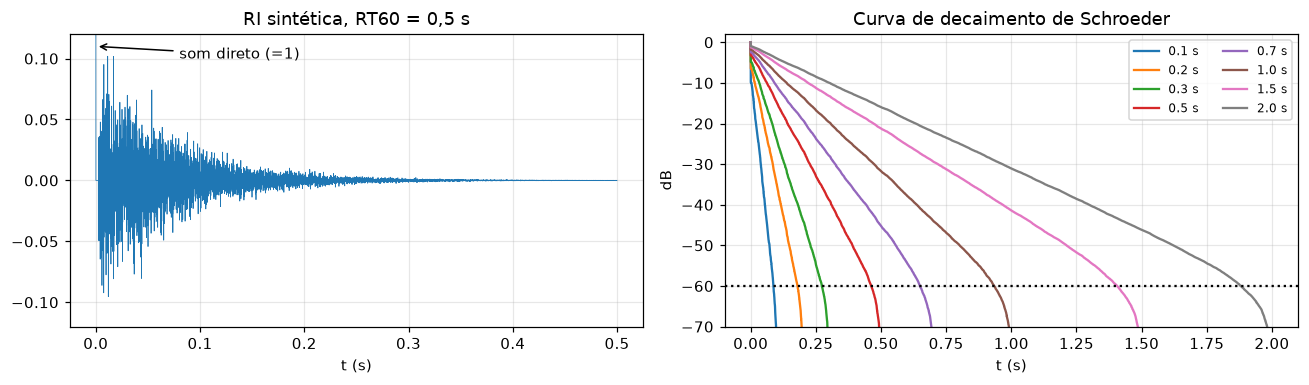

,RT60 medido (s),DRR (dB),duração da RI (s)
RT60 pedido (s),,,
0.1,0.108,7.0,0.1
0.2,0.209,4.0,0.2
0.3,0.302,2.2,0.3
0.5,0.488,0.0,0.5
0.7,0.696,-1.5,0.7
1.0,0.993,-3.0,1.0
1.5,1.503,-4.8,1.5
2.0,1.992,-6.0,2.0


In [5]:
# Verificação: o RT60 medido na RI (integral de Schroeder, ajuste −5 a −25 dB) bate com o pedido
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
tab = []
for rt in NIVEIS_RT60[1:]:
    h = resposta_impulso(rt, semente=1)
    edc = 10 * np.log10(np.cumsum(h[::-1] ** 2)[::-1] / np.sum(h ** 2))
    ax[1].plot(np.arange(len(h)) / SR, edc, label=f"{rt} s")
    tab.append({"RT60 pedido (s)": rt, "RT60 medido (s)": round(rt60_medido(h), 3),
                "DRR (dB)": round(drr_db(rt), 1), "duração da RI (s)": len(h) / SR})
h = resposta_impulso(0.5, semente=1)
ax[0].plot(np.arange(len(h)) / SR, h, lw=.5); ax[0].set(title="RI sintética, RT60 = 0,5 s", xlabel="t (s)", ylim=(-.12, .12))
ax[0].annotate("som direto (=1)", (0, .11), (.08, .1), arrowprops=dict(arrowstyle="->"))
ax[1].axhline(-60, c="k", ls=":"); ax[1].set(title="Curva de decaimento de Schroeder", xlabel="t (s)", ylabel="dB", ylim=(-70, 2))
ax[1].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame(tab).set_index("RT60 pedido (s)"))

### Exemplos audíveis de cada nível
O mesmo arquivo (locutor 0013, Neutral) em todos os níveis, e o espectrograma de três deles: a cauda "preenche" as pausas e borra as transições entre fonemas.

RT60 = 0 (seco)


RT60 = 0.1 s  (DRR = +7.0 dB)


RT60 = 0.2 s  (DRR = +4.0 dB)


RT60 = 0.3 s  (DRR = +2.2 dB)


RT60 = 0.5 s  (DRR = +0.0 dB)


RT60 = 0.7 s  (DRR = -1.5 dB)


RT60 = 1.0 s  (DRR = -3.0 dB)


RT60 = 1.5 s  (DRR = -4.8 dB)


RT60 = 2.0 s  (DRR = -6.0 dB)


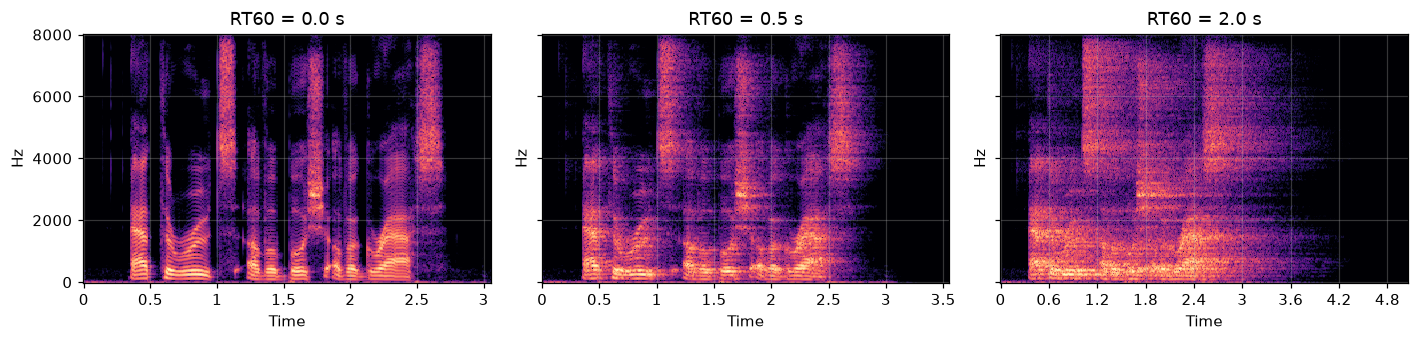

In [6]:
i_ex = int(meta.index[meta.arquivo == "0013_000020.wav"][0])
y0 = carregar_audio(meta.caminho[i_ex])
for rt in NIVEIS_RT60:
    yr = reverberar(y0, rt, semente=semente_arquivo(i_ex, rt))
    print(f"RT60 = {rt:.1f} s  (DRR = {drr_db(rt):+.1f} dB)" if rt else "RT60 = 0 (seco)")
    display(Audio(yr / max(1, np.abs(yr).max()), rate=SR))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a, rt in zip(ax, [0.0, 0.5, 2.0]):
    yr = reverberar(y0, rt, semente=semente_arquivo(i_ex, rt))
    S = librosa.amplitude_to_db(np.abs(librosa.stft(yr, n_fft=512, hop_length=160)), ref=np.max)
    librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="hz", ax=a, vmin=-70)
    a.set_title(f"RT60 = {rt} s")
plt.tight_layout(); plt.show()

## 5. Resultado central: acurácia × RT60

Cada ponto é a média das **5 divisões**; a faixa sombreada é ± 1 desvio-padrão entre divisões. Mesmo k, mesmas divisões, mesmos arquivos de teste para as duas curvas.

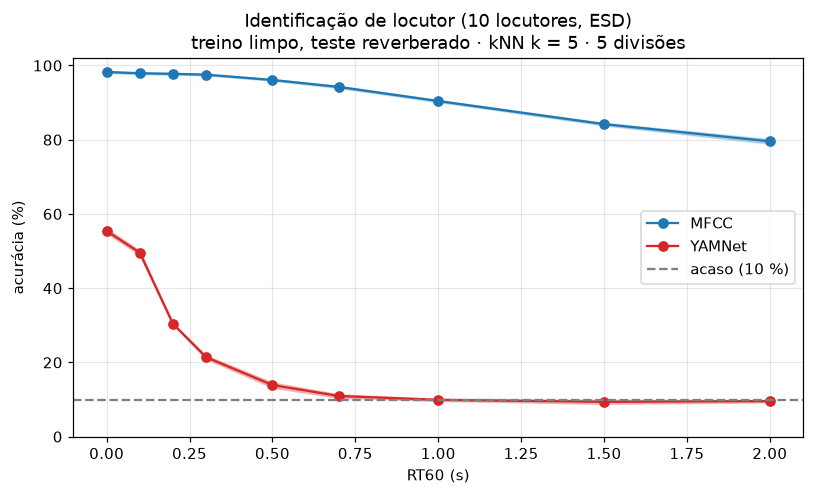

In [7]:
def grafico(df, cond, ax, titulo):
    for rep in ("MFCC", "YAMNet"):
        g = df[(df.condicao == cond) & (df.representacao == rep)].groupby("rt60").acuracia
        m, s = g.mean() * 100, g.std() * 100
        ax.plot(m.index, m, "o-", c=COR[rep], label=rep)
        ax.fill_between(m.index, m - s, m + s, color=COR[rep], alpha=.25)
    ax.axhline(10, c="gray", ls="--", label="acaso (10 %)")
    ax.set(xlabel="RT60 (s)", ylabel="acurácia (%)", ylim=(0, 102), title=titulo); ax.legend()

fig, ax = plt.subplots(figsize=(7.5, 4.6))
grafico(df_k5, "principal", ax, "Identificação de locutor (10 locutores, ESD)\ntreino limpo, teste reverberado · kNN k = 5 · 5 divisões")
plt.tight_layout(); plt.savefig("data/resultados/curva_central.png", dpi=200); plt.show()

### Variabilidade: a diferença entre as representações é maior que a dispersão?

Como as duas representações usam **as mesmas divisões**, comparamos a **diferença pareada** Δ = acc(MFCC) − acc(YAMNet) em cada divisão. Critério: a diferença é considerada maior que a dispersão quando |Δ médio| > 2 × desvio de Δ entre divisões **e** também maior que o maior desvio das duas curvas. Valores em pontos percentuais.

In [8]:
r = resumo_pareado(df_k5, "principal")
tab = (r.drop(columns="diferenca_supera_dispersao") * 100).round(1)
tab["Δ > dispersão?"] = r["diferenca_supera_dispersao"].map({True: "sim", False: "não"})
display(tab)

,MFCC_media,MFCC_desvio,YAMNet_media,YAMNet_desvio,delta_media,delta_desvio,Δ > dispersão?
rt60,,,,,,,
0.0,98.3,0.2,55.4,0.6,42.8,0.7,sim
0.1,97.9,0.2,49.6,0.6,48.3,0.8,sim
0.2,97.8,0.2,30.4,0.2,67.4,0.4,sim
0.3,97.5,0.2,21.4,0.5,76.1,0.4,sim
0.5,96.1,0.2,13.9,0.7,82.2,0.8,sim
0.7,94.2,0.3,10.9,0.5,83.3,0.7,sim
1.0,90.4,0.3,9.9,0.3,80.5,0.3,sim
1.5,84.2,0.3,9.4,0.5,74.8,0.6,sim
2.0,79.6,0.6,9.6,0.3,70.0,0.8,sim


**Leitura.**
- **Em todos os níveis a diferença é dezenas de vezes maior que a dispersão** (desvios entre divisões < 1 ponto; Δ entre 43 e 83 pontos). Não há nível em que as duas representações sejam estatisticamente indistinguíveis.
- **O YAMNet despenca cedo**: perde 6 pontos com RT60 = 0,1 s, cai à metade com 0,2 s (55 → 30 %) e chega ao **acaso a partir de RT60 ≈ 0,7–1,0 s**.
- **O MFCC médio é robusto**: praticamente intacto até 0,3 s (98 → 97,5 %), 96 % em 0,5 s e ainda **80 % com RT60 = 2 s**.
- A diferença Δ **cresce** até RT60 ≈ 0,7 s (83 pontos) e só depois diminui — não porque o YAMNet melhore, mas porque ele já está no acaso e o MFCC continua caindo. **As curvas não se cruzam.**

### Condição pareada e robustez a k
À esquerda, treino e teste reverberados no mesmo RT60; à direita, a condição principal com k = 1.

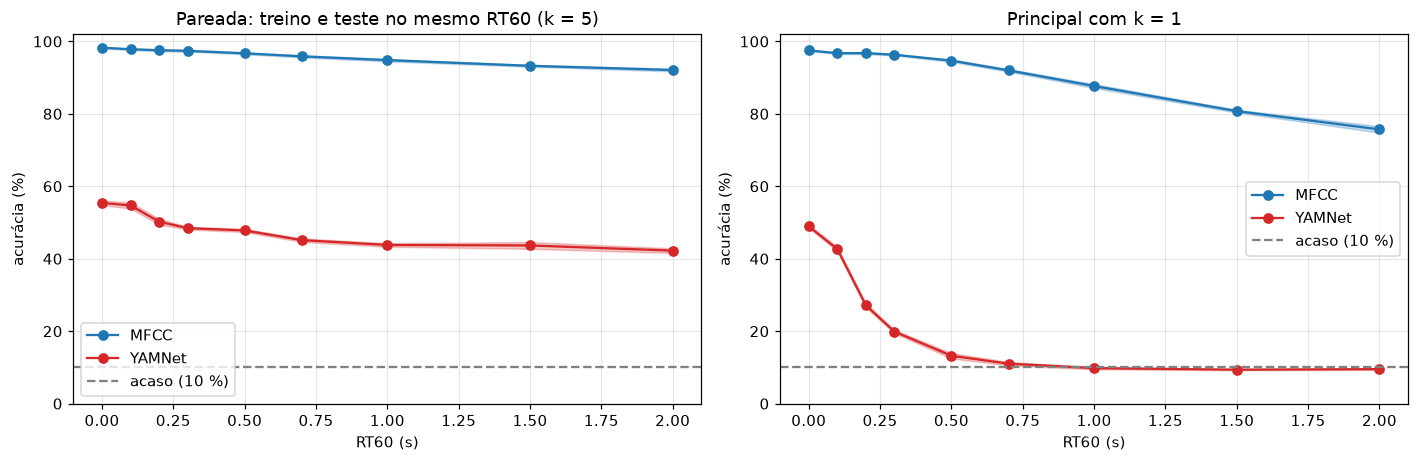

Pareada, k=5 (%):


rt60,0.0,0.1,0.2,0.3,0.5,0.7,1.0,1.5,2.0
MFCC_media,98.3,97.8,97.6,97.4,96.7,95.9,94.8,93.3,92.1
YAMNet_media,55.4,54.7,50.2,48.4,47.8,45.1,43.8,43.7,42.2


In [9]:
df_k1 = avaliar_curvas(y, X, divisoes, k=1)
df_k1.to_csv("data/resultados/curvas_k1.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
grafico(df_k5, "pareada", ax[0], "Pareada: treino e teste no mesmo RT60 (k = 5)")
grafico(df_k1, "principal", ax[1], "Principal com k = 1")
plt.tight_layout(); plt.show()
print("Pareada, k=5 (%):"); display((resumo_pareado(df_k5, "pareada")[["MFCC_media", "YAMNet_media"]] * 100).round(1).T)

- **k não muda a conclusão** (com k = 1 as curvas ficam 1–7 pontos abaixo, mesma forma).
- **Na condição pareada o YAMNet mantém 42–55 %**: a informação de locutor **continua lá** no embedding reverberado. O colapso da condição principal é, portanto, um **descasamento de domínio**: a reverberação **desloca** os embeddings para uma região que não corresponde a nenhum locutor do treino limpo. A seção 6 mede esse deslocamento.

## 6. Por que: diagnósticos

### 6.1 Geometria — quanto a reverberação desloca os pontos, comparado à distância entre locutores
No espaço z-score (média e desvio do treino limpo), medimos: o **deslocamento** médio dos vetores de teste ‖média(reverberado) − média(limpo)‖; a **distância média entre centróides** de locutores; e a **dispersão dentro** de cada locutor. Se o deslocamento é maior que a distância entre locutores, o vizinho mais próximo passa a ser decidido pela direção do deslocamento, e não pela identidade.

In [10]:
tr, te = divisoes[0]
geo = pd.DataFrame([{"representação": rep, "RT60": rt, **geometria(X[(rep, 0.0)], X[(rep, rt)], y, tr, te)}
                    for rep in ("MFCC", "YAMNet") for rt in NIVEIS_RT60[1:]])
display(geo.pivot(index="RT60", columns="representação", values="razao_desloc_entre").round(2)
        .rename(columns=lambda c: f"{c}: deslocamento / dist. entre locutores"))

representação,MFCC: deslocamento / dist. entre locutores,YAMNet: deslocamento / dist. entre locutores
RT60,,
0.1,0.07,0.780000
0.2,0.14,3.890000
0.3,0.20,8.060000
0.5,0.30,15.330000
0.7,0.37,21.080000
1.0,0.46,27.760000
1.5,0.55,34.830002
2.0,0.61,39.450001


- **MFCC:** o deslocamento é **0,07–0,6×** a distância entre locutores → os locutores continuam separáveis.
- **YAMNet:** a razão já é **≈ 4 em RT60 = 0,2 s** e passa de **15 em 0,5 s**. O espaço do YAMNet tem pouca separação entre locutores (dispersão dentro de cada locutor ≈ 2× a distância entre centróides — por isso só 55 % no áudio limpo) e muita sensibilidade à sala.

### 6.2 Por que o MFCC *médio* quase não se move: o argumento espectral
A média temporal dos MFCC é, essencialmente, a DCT do **log-espectro médio de longo prazo** (LTAS) da voz — a "cor média" do trato vocal de cada pessoa. Para uma convolução, $X_r(f) = X(f)\,H(f)$ e, em potência média, $\overline{|X_r|^2} \approx \overline{|X|^2}\;\mathbb E|H(f)|^2$. Na nossa RI, $b[n]$ é ruído **branco**: $\mathbb E|H(f)|^2 = 1 + g^2\sum e^{\dots}$ é **constante em frequência**. Logo a reverberação quase não muda a forma do LTAS — muda o *tempo* (borra transições, preenche pausas), e é justamente a informação temporal que a média descarta.

O que muda é o preenchimento das pausas: quadros que antes eram silêncio passam a ter energia de voz reverberada. Isso aparece como deslocamento sobretudo em $c_0$ (energia) e $c_1$ (inclinação espectral), e é **quase igual para todos os locutores** — comparável a uma constante somada no cepstro.

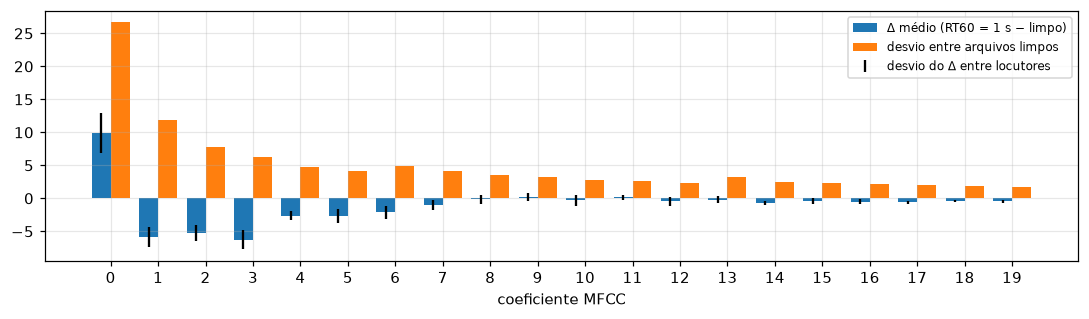

In [11]:
d = deslocamento_mfcc(X[("MFCC", 0.0)], X[("MFCC", 1.0)], y)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(d.index - .2, d.delta_medio, .4, label="Δ médio (RT60 = 1 s − limpo)")
ax.bar(d.index + .2, d.desvio_entre_arquivos_limpos, .4, label="desvio entre arquivos limpos")
ax.errorbar(d.index - .2, d.delta_medio, d.desvio_entre_locutores, fmt="none", c="k", label="desvio do Δ entre locutores")
ax.set(xlabel="coeficiente MFCC", xticks=range(20)); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

O deslocamento médio (azul) é pequeno diante da variação natural de cada coeficiente (laranja), e **varia pouco de locutor para locutor** (barras pretas) — por isso a ordem relativa entre locutores se preserva.

**Limitação importante (e previsão para salas reais):** nossa cauda é espectralmente plana. Em salas reais as altas frequências decaem mais rápido (absorção do ar e das superfícies), o que **inclina** o LTAS e mudaria $c_1, c_2, \dots$ de forma sistemática. Esperamos que, com RIs reais ou com decaimento dependente da frequência, o MFCC médio caia mais cedo do que aqui.

### 6.3 Por que o YAMNet se move tanto
O YAMNet não olha para o espectro médio: olha para **padrões tempo-frequência** de 0,96 s no log-mel (ataques, transições de formantes, harmônicos), que é exatamente o que a reverberação destrói. Duas verificações:

**(a) O que o próprio YAMNet "ouve".** Score médio de algumas classes do AudioSet em 150 arquivos:

In [12]:
sc = scores_yamnet(meta, [0.0, 0.1, 0.2, 0.5, 1.0, 2.0], n=150)
display(sc.round(3))

,Speech,Reverberation,Echo,"Inside, small room","Inside, large room or hall",Silence
rt60,,,,,,
0.0,0.979,0.000,0.000,0.006,0.001,0.004
0.1,0.969,0.000,0.000,0.008,0.001,0.011
0.2,0.926,0.000,0.000,0.013,0.001,0.041
0.5,0.792,0.000,0.000,0.016,0.002,0.125
1.0,0.623,0.000,0.001,0.009,0.005,0.197
2.0,0.334,0.001,0.002,0.006,0.010,0.277


A probabilidade de **Speech** cai de 0,98 para ≈ 0,33 com RT60 = 2 s, e a de **Silence** sobe — para a rede, a voz reverberada é "menos fala". Já as classes **Reverberation / Echo / Inside room** quase não reagem a esta reverberação sintética, então o embedding não está simplesmente "detectando a sala": é a representação de fala inteira que se desloca.

**(b) Não é artefato do z-score nem da cauda.**

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
def acc_sem_z(rep, rt, norm):
    Xtr, Xte = X[(rep, 0.0)][tr], X[(rep, rt)][te]
    if norm == "z":  s = StandardScaler().fit(Xtr); Xtr, Xte = s.transform(Xtr), s.transform(Xte)
    if norm == "L2": Xtr, Xte = [M / np.linalg.norm(M, axis=1, keepdims=True) for M in (Xtr, Xte)]
    return (KNeighborsClassifier(K).fit(Xtr, y[tr]).predict(Xte) == y[te]).mean() * 100
niv = [0.0, 0.2, 0.5, 1.0, 2.0]
display(pd.DataFrame({f"{rep} · {nm}": [acc_sem_z(rep, rt, nm) for rt in niv]
                      for rep in ("MFCC", "YAMNet") for nm in ("z", "nenhuma", "L2")}, index=niv).T.round(1)
        .rename_axis("normalização \\ RT60"))

_, _, Xs = carregar(pasta_reverb="data/features_reverb_semcauda", niveis=[0.2, 0.5, 1.0, 2.0])
df_sc = avaliar_curvas(y, Xs, divisoes, niveis=[0.0, 0.2, 0.5, 1.0, 2.0], k=K)
comp = pd.concat({"cauda mantida": df_k5[df_k5.rt60.isin(niv)], "cauda cortada": df_sc})
comp = comp[comp.condicao == "principal"].reset_index(level=0).rename(columns={"level_0": "versão"})
display((comp.pivot_table(index=["representacao", "versão"], columns="rt60", values="acuracia") * 100).round(1))

,0.0,0.2,0.5,1.0,2.0
normalização \ RT60,,,,,
MFCC · z,98.4,97.8,96.1,90.8,80.2
MFCC · nenhuma,93.5,91.8,85.8,75.6,63.8
MFCC · L2,95.4,94.1,88.9,77.7,65.0
YAMNet · z,54.9,30.0,14.8,10.2,9.9
YAMNet · nenhuma,54.7,30.1,15.9,9.5,9.1
YAMNet · L2,55.7,30.2,16.0,11.0,9.8


rt60                          0.0   0.2   0.5   1.0   2.0
representacao versão                                     
MFCC          cauda cortada  98.3  97.7  95.1  87.8  80.2
              cauda mantida  98.3  97.8  96.1  90.4  79.6
YAMNet        cauda cortada  55.4  34.1  21.5  16.3  11.0
              cauda mantida  55.4  30.4  13.9   9.9   9.6

- Sem normalização e com normalização L2, o YAMNet colapsa do mesmo jeito → o z-score (exigido pelo enunciado) não é a causa. (Para o MFCC, o z-score ajuda, pois equaliza a escala de $c_0$.)
- **Ablação da cauda:** cortando o áudio reverberado no comprimento original (sem os ~RT60 s finais de cauda pura), o YAMNet melhora só alguns pontos (p. ex. 15 → 22 % em 0,5 s) e continua perto do acaso em 2 s. A cauda final pesa (com RT60 = 2 s ela é ~40 % dos patches de 0,96 s), mas **o principal é a reverberação dentro da fala**.

## 7. Análise de falhas no nível em que as curvas se separam

Escolhemos **RT60 = 0,2 s**: é o primeiro nível em que as curvas se afastam de verdade (Δ salta de 48 para 67 pontos; o YAMNet cai à metade enquanto o MFCC perde menos de 1 ponto). Divisão 0, condição principal.

,nº de arquivos de teste
categoria,
só MFCC acerta,3601
os dois acertam,1536
os dois erram,72
só YAMNet acerta,41


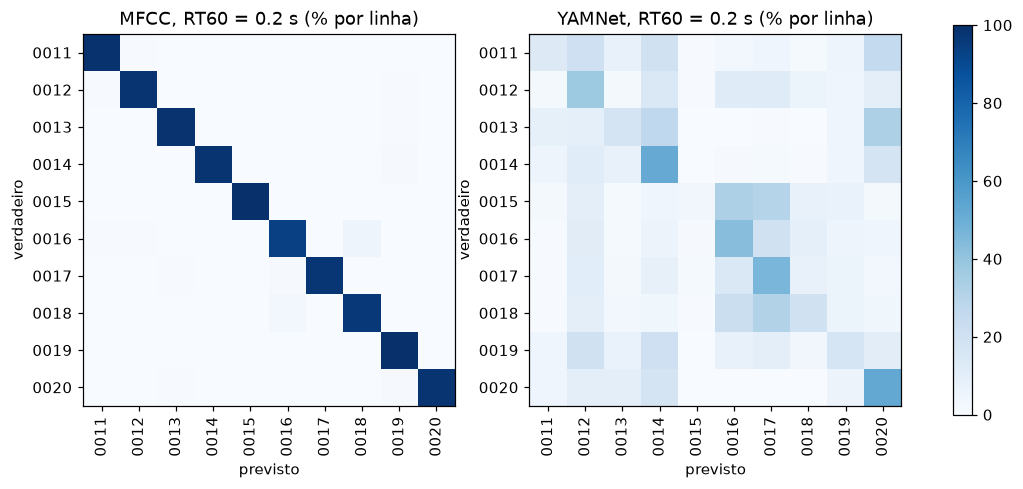

Para onde vão os erros do YAMNet: {'0014': 631, '0012': 586, '0017': 573, '0020': 572}
Para onde vão os erros do MFCC:   {'0018': 27, '0016': 23, '0019': 21, '0011': 11}


In [14]:
RT_F = 0.2
_, P = avaliar_curvas(y, X, divisoes[:1], niveis=[RT_F], k=K, guardar_predicoes=True)
te0, pm = P[("principal", "MFCC", RT_F, 0)]; _, py = P[("principal", "YAMNet", RT_F, 0)]
cat = categorias_acerto(y, te0, pm, py); cat["emocao"] = meta.emocao.to_numpy()[te0]
display(cat.categoria.value_counts().to_frame("nº de arquivos de teste"))

from sklearn.metrics import confusion_matrix
locs = sorted(set(y))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, (rep, col) in zip(ax, (("MFCC", "pred_MFCC"), ("YAMNet", "pred_YAMNet"))):
    cm = confusion_matrix(cat.verdadeiro, cat[col], labels=locs, normalize="true") * 100
    im = a.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    a.set(xticks=range(10), yticks=range(10), xticklabels=locs, yticklabels=locs,
          xlabel="previsto", ylabel="verdadeiro", title=f"{rep}, RT60 = {RT_F} s (% por linha)")
    a.tick_params(axis="x", rotation=90); a.grid(False)
plt.colorbar(im, ax=ax); plt.show()
print("Para onde vão os erros do YAMNet:", cat[cat.pred_YAMNet != cat.verdadeiro].pred_YAMNet.value_counts().head(4).to_dict())
print("Para onde vão os erros do MFCC:  ", cat[cat.pred_MFCC != cat.verdadeiro].pred_MFCC.value_counts().head(4).to_dict())

- **YAMNet:** os erros se acumulam em poucas colunas — 4 locutores (0014, 0012, 0017, 0020) recebem ≈ 64 % dos erros em 0,2 s (e em 1,0 s um único locutor, 0014, recebe metade). É a assinatura do deslocamento comum da seção 6.1: todos os pontos reverberados migram para a mesma região, e os locutores do treino mais próximos dela "capturam" o teste. Por isso a acurácia por locutor fica muito desigual: ≈ 50 % para 0014 e 0020 (os "atratores") e 3 % para 0015.
- **MFCC:** os poucos erros (113 de 5 250) são quase todos **entre dois locutores específicos: 0016 ↔ 0018** (39 dos 113), as duas vozes mais agudas do conjunto (F0 ≈ 204 e 243 Hz) — uma confusão "de vizinhos", não um deslocamento global.

### F0 dos locutores: os erros respeitam a altura da voz?

In [15]:
f0 = f0_mediana_por_locutor(meta, n_por_locutor=10)
display(f0.round(0).to_frame().T)
todos_pares = np.mean([abs(f0[a] - f0[b]) for a in locs for b in locs if a != b])
for rep, col in (("MFCC", "pred_MFCC"), ("YAMNet", "pred_YAMNet")):
    e = cat[cat[col] != cat.verdadeiro]
    dF0 = np.abs(f0[e.verdadeiro].to_numpy() - f0[e[col]].to_numpy()).mean()
    print(f"{rep}: |ΔF0| médio entre verdadeiro e previsto nos erros = {dF0:.0f} Hz "
          f"(média entre pares quaisquer de locutores = {todos_pares:.0f} Hz) · n = {len(e)}")
print("\nTaxa de erro por emoção (%):")
display(pd.DataFrame({rep: (1 - (cat[col] == cat.verdadeiro).groupby(cat.emocao).mean()) * 100
                      for rep, col in (("MFCC", "pred_MFCC"), ("YAMNet", "pred_YAMNet"))}).T.round(1))

,0011,0012,0013,0014,0015,0016,0017,0018,0019,0020
F0_mediana_Hz,123.0,164.0,115.0,144.0,197.0,204.0,189.0,243.0,141.0,98.0


MFCC: |ΔF0| médio entre verdadeiro e previsto nos erros = 39 Hz (média entre pares quaisquer de locutores = 55 Hz) · n = 113
YAMNet: |ΔF0| médio entre verdadeiro e previsto nos erros = 36 Hz (média entre pares quaisquer de locutores = 55 Hz) · n = 3673

Taxa de erro por emoção (%):


emocao,Angry,Happy,Neutral,Sad,Surprise
MFCC,2.4,2.1,1.2,2.0,3.0
YAMNet,73.0,73.2,68.1,64.6,71.1


### Exemplos audíveis
Dois exemplos de cada categoria (limpo e reverberado a 0,2 s). Os arquivos também ficam em `data/fallas/`.

In [16]:
rng = np.random.default_rng(7)
ex = pd.concat([g.iloc[rng.choice(len(g), size=min(2, len(g)), replace=False)]
                for _, g in cat.groupby("categoria")])
ex = exportar_exemplos(meta, ex, RT_F)
ordem = ["só MFCC acerta", "só YAMNet acerta", "os dois erram", "os dois acertam"]
for c in ordem:
    display(Markdown(f"#### {c}"))
    for _, r in ex[ex.categoria == c].iterrows():
        display(Markdown(f"`{meta.arquivo[r.idx]}` · {r.emocao} · verdadeiro **{r.verdadeiro}** "
                         f"(F0 ≈ {f0[r.verdadeiro]:.0f} Hz) → MFCC **{r.pred_MFCC}** · YAMNet **{r.pred_YAMNet}**"))
        display(Audio(r.wav_limpo)); display(Audio(r.wav_reverb))

#### só MFCC acerta

`0017_000697.wav` · Angry · verdadeiro **0017** (F0 ≈ 189 Hz) → MFCC **0017** · YAMNet **0014**

`0014_000940.wav` · Happy · verdadeiro **0014** (F0 ≈ 144 Hz) → MFCC **0014** · YAMNet **0019**

#### só YAMNet acerta

`0014_001551.wav` · Surprise · verdadeiro **0014** (F0 ≈ 144 Hz) → MFCC **0019** · YAMNet **0014**

`0018_001295.wav` · Sad · verdadeiro **0018** (F0 ≈ 243 Hz) → MFCC **0011** · YAMNet **0018**

... (2 outputs left out)

`0020_000403.wav` · Angry · verdadeiro **0020** (F0 ≈ 98 Hz) → MFCC **0011** · YAMNet **0014**

#### os dois acertam

`0013_001401.wav` · Surprise · verdadeiro **0013** (F0 ≈ 115 Hz) → MFCC **0013** · YAMNet **0013**

`0018_001145.wav` · Sad · verdadeiro **0018** (F0 ≈ 243 Hz) → MFCC **0018** · YAMNet **0018**

**Explicação acústica dos casos** (características medidas sobre todos os arquivos de cada categoria na divisão 0, não só nos exemplos):
- **Só MFCC acerta — 3 601 arquivos (69 % do teste).** Com 0,2 s a reverberação soa como uma sala pequena: o timbre médio da voz (formantes, inclinação espectral), que é o que o MFCC médio guarda, quase não muda. Já o YAMNet vê os padrões tempo-frequência de cada patch de 0,96 s borrados — ataques e transições de formantes se espalham — e o embedding sai da região "deste locutor" em direção aos atratores (nos exemplos, 0017 e 0014 viram 0014 e 0019).
- **Só YAMNet acerta — 41 arquivos (< 1 %).** Predominam **Sad e Surprise** (25 de 41) e arquivos mais curtos que a média (2,55 s contra 2,83 s). Num arquivo curto, a média do MFCC tem menos quadros e pesa mais as pausas e o final, justamente as partes que a cauda preenche; além disso, emoções extremas deslocam o timbre do próprio locutor para perto do de outro. O MFCC então troca para um locutor vizinho (em 25 dos 41 casos, para 0018 ou 0019), enquanto o YAMNet acerta porque o locutor verdadeiro é um dos "atratores" (0016, 0014, 0017 somam 26 dos 41).
- **Os dois erram — 72 arquivos.** 56 dos 72 são emoções de **alta excitação** (Surprise, Angry, Happy), que mudam o esforço vocal e o timbre (mais energia em alta frequência). Os locutores mais envolvidos são 0016 e 0018 — o par de vozes agudas que o MFCC já confunde no limpo.
- **Os dois acertam — 1 536 arquivos.** São sobretudo dos locutores cujo embedding fica na direção do deslocamento (0014, 0020, 0017, 0016 têm 43–52 % de acerto no YAMNet) e que o MFCC separa bem.
- **F0:** nos erros, |ΔF0| entre o locutor verdadeiro e o previsto (≈ 36–39 Hz) é menor que entre um par qualquer de locutores (55 Hz): as duas representações, quando erram, erram para vozes de altura parecida.

## 8. Previsto × observado

| | Previsto (23/10) | Observado |
|---|---|---|
| quem cai primeiro | MFCC | **YAMNet** — já em RT60 = 0,1–0,2 s |
| a partir de quando | MFCC a partir de ≈ 0,3–0,5 s | YAMNet perde metade em 0,2 s e chega ao acaso em ≈ 0,7 s; MFCC só cai de forma visível acima de 0,5 s |
| forma | as duas caem; YAMNet mais devagar | MFCC cai suave e quase linear (98 → 80 % em 2 s); YAMNet cai em degrau |
| ponto de partida | os dois altos | MFCC 98 %, YAMNet 55 % |

**O que estava errado no raciocínio.**
1. *"O MFCC usa janelas de 25 ms e a cauda mistura quadros vizinhos."* Verdade quadro a quadro — mas o baseline é a **média** no tempo. A média só vê o espectro de longo prazo, que uma reverberação espectralmente plana quase não altera (seção 6.2). Esquecemos que a média descarta exatamente o que a reverberação estraga. (A justificativa original falava ainda de prosódia, que importa para emoção, não para identidade do locutor.)
2. *"O YAMNet viu ambientes variados no AudioSet, então é robusto."* O treino o tornou robusto **para dizer qual é o tipo de som** — e mesmo isso degrada (o score de *Speech* cai para 0,33 em 2 s). Nada no treino pede que a **penúltima camada** preserve a identidade do locutor sob mudança de sala: a informação de locutor é um resíduo fraco (55 % no limpo) e o deslocamento causado pela sala é muito maior que ele (seção 6.1).
3. *Não separamos* "informação destruída" de "informação deslocada". A condição pareada mostra que o YAMNet reverberado ainda contém ≈ 45 % de informação de locutor: a falha é de **descasamento** treino-teste.

## Conclusões
- Para identificar locutores com kNN, o **vetor de MFCC médios é muito mais robusto à reverberação** que o embedding do YAMNet: 80 % contra o acaso (10 %) em RT60 = 2 s. A diferença é muito maior que a variabilidade entre divisões em **todos** os níveis.
- O YAMNet é uma representação de **"que som é"**, não de **"quem fala"**; sob reverberação, o deslocamento do embedding é até 40× maior que a distância entre locutores.
- **Limitações:** (i) RI sintética com decaimento igual em todas as frequências — com RIs reais esperamos uma queda mais cedo do MFCC; (ii) DRR acoplado ao RT60 (uma única sala/distância); (iii) ESD é gravado em estúdio com sessões por locutor, e o canal pode ajudar a identificação; (iv) uma única realização de RI por arquivo e nível.
- **Próximos passos naturais:** RIs medidas (p. ex. bases públicas de RIR), decaimento dependente da frequência, normalização cepstral (CMN) no MFCC e embeddings treinados para locutor (x-vectors/ECAPA) como terceira curva.